<a href="https://colab.research.google.com/github/syeda-bisma05/ecommerce-customer-eda/blob/main/ecommerce_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#E-commerce Customer Behavior and Purchase Pattern Analysis
This notebook analyzes customer behavior and purchase patterns of an online store using the Ecommerce Customers dataset (500 customers).
## Project Questions:
### Univariate (one column)
1. What is the typical (mean and median) Yearly Amount Spent, and is the data skewed?
2. What is the typical Avg. Session Length, and in which range do most customers fall?
3. How long are customers members (Length of Membership), and are there more new or long-term customers?

### Bivariate (two columns)
4. Does more Time on App go with a higher Yearly Amount Spent?
5. Does more Time on Website go with a higher Yearly Amount Spent?
6. What is the relationship between Length of Membership and Yearly Amount Spent?

### My own questions
7. How do the top 10% spenders differ from other customers in Time on App, Time on Website and Length of Membership?
8. Which numeric column has the strongest relationship with Yearly Amount Spent (correlation ranking)?

In [ ]:
from google.colab import files
files.upload()


In [ ]:
!pip install panda numpy matplotlib seaborn plotly

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Step 1: Basic Analysis
Here we check the shape, column names, data types and a summary of the data.

In [5]:
df = pd.read_csv('ecommerce_customers.csv')

In [6]:
df.shape

(500, 8)

In [7]:
df.columns

Index(['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App',
       'Time on Website', 'Length of Membership', 'Yearly Amount Spent'],
      dtype='object')

In [8]:
df.dtypes

,0
Email,object
Address,object
Avatar,object
Avg. Session Length,float64
Time on App,float64
Time on Website,float64
Length of Membership,float64
Yearly Amount Spent,float64


**Observation:** The dataset has 8 columns. Three columns (Email, Address, Avatar) are `object` type, which means text. The other five (Avg. Session Length, Time on App, Time on Website, Length of Membership, Yearly Amount Spent) are `float64`, which means decimal numbers. So we have 5 numeric columns to use for graphs and correlation, and the text columns are only identifiers.

All numeric columns are already `float64` and thetext columns are `object`, so no data type conversion is needed.

In [9]:
df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


**Observation:** All five numeric columns have a count of 500, so no values are missing. The average Yearly Amount Spent is about \$499 and the median is about \$499, so the data is almost symmetric (not skewed). Spending ranges from about \$257 to \$766. Avg. Session Length (about 33 minutes), Time on App (about 12 minutes), Time on Website (about 37 minutes) and Length of Membership (about 3.5 years) all have a mean close to the median and a standard deviation of about 1, so they are spread tightly around the average. Customers spend more time on the website than on the app.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


**Observation:** The dataset has 500 rows (index 0 to 499) and 8 columns. Every column shows 500 non-null values, so there are no missing values in any column. There are 5 numeric columns (float64) and 3 text columns (object: Email, Address, Avatar). The dataset uses only about 31 KB of memory, so it is small and fast to analyze.
## Step 2: Missing Values

In [11]:
df.isnull().sum()

,0
Email,0
Address,0
Avatar,0
Avg. Session Length,0
Time on App,0
Time on Website,0
Length of Membership,0
Yearly Amount Spent,0


**Observation (missing values):** Every column has 0 missing values, which matches the info() output (500 non-null in all columns). So no rows need to be dropped and nothing needs to be filled. Dropping or filling would only remove or invent data, so the best decision is to keep the data as it is.
## Step 3: Repeated Values

In [15]:
df.duplicated().sum()

np.int64(0)

In [13]:
df["Email"].duplicated().sum()

np.int64(0)

In [14]:
df["Email"].nunique()

500

**Observation (duplicates):** There are 0 duplicate rows and 0 repeated Email addresses. The Email column has 500 unique values for 500 rows, so every row is a different customer. No duplicates found, so nothing needs to be removed.
## Step 4: Outliers

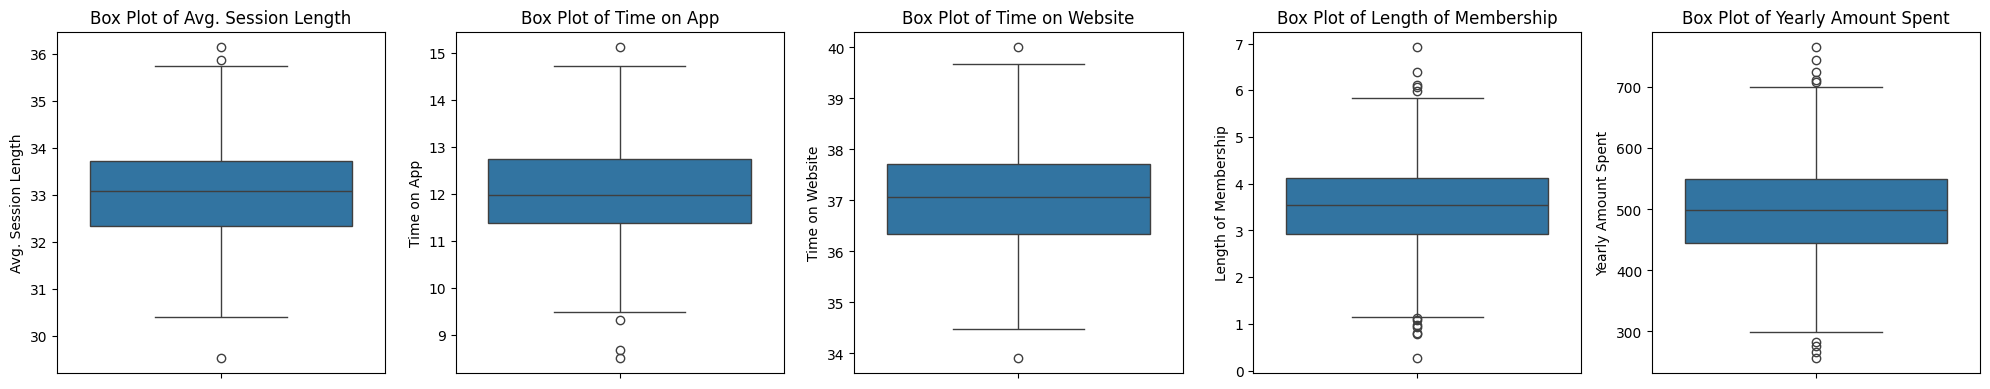

In [16]:
num_cols = ["Avg. Session Length", "Time on App", "Time on Website",
            "Length of Membership", "Yearly Amount Spent"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title("Box Plot of " + col)
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

**Observation (box plots):** In all five columns the median line sits near the center of the box and the whiskers are almost equal in length, so the data is fairly symmetric. Only a few points fall outside the whiskers. Time on Website has the fewest (about one on each side). Avg. Session Length and Time on App have a few points on one or both sides. Length of Membership and Yearly Amount Spent have the most, with several points both above and below the whiskers. The outlier points are close to the whiskers and none is extremely far away, so they look like natural variation rather than errors.

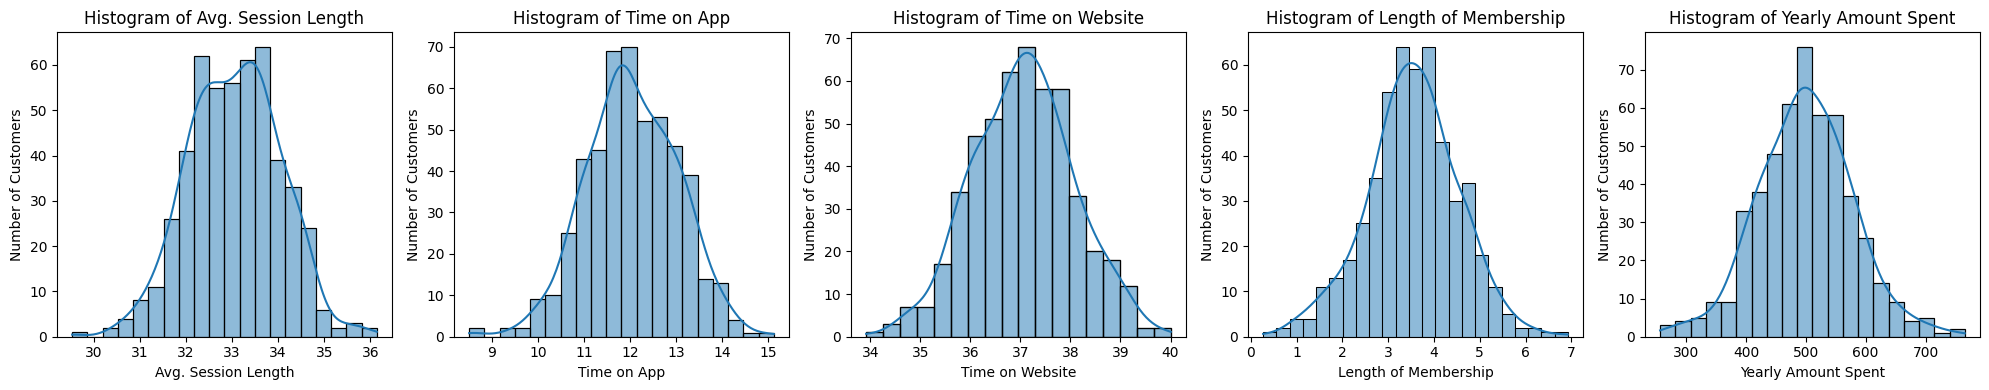

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title("Histogram of " + col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Customers")
plt.tight_layout()
plt.show()

**Observation (histograms):** All five histograms have a bell shape with a single peak in the middle, so the data is close to a normal distribution and not strongly skewed. Avg. Session Length is centered around 33 minutes, Time on App around 12 minutes, Time on Website around 37 minutes and Length of Membership around 3.5 years. Yearly Amount Spent is centered around 500 dollars. Length of Membership and Yearly Amount Spent have a slightly longer tail on the right side, which means a few customers have a longer membership and higher spending than most.

In [19]:
rows = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    rows.append([col, round(lower, 2), round(upper, 2), count])

iqr_table = pd.DataFrame(rows, columns=["Column", "Lower Limit", "Upper Limit", "Outliers"])
iqr_table


,Column,Lower Limit,Upper Limit,Outliers
0,Avg. Session Length,30.29,35.77,3
1,Time on App,9.34,14.80,4
2,Time on Website,34.30,39.77,2
3,Length of Membership,1.14,5.92,12
4,Yearly Amount Spent,288.62,705.73,9


**Observation (IQR rule):** The IQR rule was applied to all five numeric columns. Time on Website has the fewest outliers (2) and Length of Membership has the most (12), followed by Yearly Amount Spent (9). In total there are 30 outlier values out of 500 rows, which is only about 6 percent.

**Decision: keep the outliers.** The outlier values are close to the limits and are realistic values (for example, a customer with a very long membership or high spending). They are not errors or impossible values. Since the dataset is small (500 rows), removing rows would lose real customer information. The histograms also show a near-normal shape, so these few points do not distort the analysis.